In [1]:
import subprocess, sys

def install(pkg):
    print(f"Installing {pkg}...")
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", pkg, "-q"],
        capture_output=True, text=True, timeout=180
    )
    print(f"  Done.")

install("ftfy")
install("regex")
install("tqdm")
install("git+https://github.com/openai/CLIP.git")
install("loralib")

import clip, loralib
print("✓ All packages ready")
print(f"  CLIP models: {clip.available_models()}")


Installing ftfy...
  Done.
Installing regex...
  Done.
Installing tqdm...
  Done.
Installing git+https://github.com/openai/CLIP.git...
  Done.
Installing loralib...
  Done.
✓ All packages ready
  CLIP models: ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


In [2]:
import os, random, sys
import numpy as np
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('Base imports done.')

Using device: cuda
CUDA available: True
GPU: Tesla T4
Base imports done.


In [3]:
# CLIP import — downloads ~600MB on first run, may take 2-3 min
print('Loading CLIP... (may take 2-3 min on first run)')
import clip
import loralib as lora
print(f'✓ CLIP ready. Models: {clip.available_models()}')

Loading CLIP... (may take 2-3 min on first run)
✓ CLIP ready. Models: ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


In [4]:
import os, random, sys
import numpy as np
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('Base imports done.')

Using device: cuda
CUDA available: True
GPU: Tesla T4
Base imports done.


In [5]:
class Config:
    # ── Paths (adjust these to your Kaggle dataset mount points) ──
    PASCAL_IMG_DIR   = '/kaggle/input/datasets/huanghanchina/pascal-voc-2012/VOC2012/JPEGImages'
    PASCAL_MASK_DIR  = '/kaggle/input/datasets/huanghanchina/pascal-voc-2012/VOC2012/SegmentationClass'
    PASCAL_SPLIT_DIR = '/kaggle/input/datasets/huanghanchina/pascal-voc-2012/VOC2012/ImageSets/Segmentation'

    # SBD augmented masks (downloaded via wget to /kaggle/working)
    SBD_MASK_DIR     = '/kaggle/working/VOCdevkit/VOC2012/SegmentationClassAug'
    SBD_SPLIT_FILE   = '/kaggle/working/train_aug.txt'  # optional; auto-discovered if missing

    # ── WBC Dataset ──
    # Structure: Dataset 1/ and Dataset 2/ — .bmp=image, .png=mask, SAME folder
    WBC_DIR1         = '/kaggle/working/segmentation_WBC/Dataset 1'
    WBC_DIR2         = '/kaggle/working/segmentation_WBC/Dataset 2'
    # CHAOS T2 root
    CHAOS_T2_ROOT    = '/kaggle/input/datasets/anhoangvo/chaos-t1-and-t2/chaos/t2'

    # Add on Kaggle: anhoangvo/chaos-t1-and-t2


    ISIC_IMG_DIR     = '/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input'
    ISIC_MASK_DIR    = '/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1_Training_GroundTruth'

    # ── Training ──
    IMG_SIZE        = 473          # resize all images to 400x400
    BATCH_SIZE      = 4
    N_EPISODES      = 1000          # training episodes per epoch
    N_EPOCHS        = 30
    LR              = 1e-4
    SHOT            = 1            # 1-shot or 5-shot
    N_WAY           = 1

    # ── CD-TG ──
    ALPHA           = 0.3          # fixed alpha for baseline CD-TG
    USE_DMW         = False         # Baseline: fixed alpha only
    CLIP_MODEL      = 'ViT-B/16'
    FEATURE_DIM     = 512          # CLIP & visual feature dimension
    LORA_RANK       = 4

    # ── RPMM ──
    N_PROTOTYPES    = 2            # K prototypes per class in RPMMs

    # ── PASCAL VOC 20 classes split into 4 folds ──
    VOC_CLASSES = [
        'background','aeroplane','bicycle','bird','boat','bottle',
        'bus','car','cat','chair','cow','diningtable','dog','horse',
        'motorbike','person','pottedplant','sheep','sofa','train','tvmonitor'
    ]
    # 4 folds; fold 0 is val, rest are train
    VOC_FOLD = 0
    VOC_TRAIN_IDS = list(range(1, 16))   # class ids 1–15 for training
    VOC_VAL_IDS   = list(range(16, 21))  # class ids 16–20 for val

    # ── ISIC categories ──
    ISIC_CLASSES = ['melanoma', 'nevus', 'seborrheic_keratosis']

cfg = Config()
print('Config loaded.')
print(f'USE_DMW (our novelty): {cfg.USE_DMW}')
cfg.CXR_IMG_DIR  = '/kaggle/input/datasets/nikhilpandey360/chest-xray-masks-and-labels/data/Lung Segmentation/CXR_png'
cfg.CXR_MASK_DIR = '/kaggle/input/datasets/nikhilpandey360/chest-xray-masks-and-labels/data/Lung Segmentation/masks'
print('CXR paths added.')


Config loaded.
USE_DMW (our novelty): False
CXR paths added.


In [6]:
# These descriptions follow the paper's TGU format:
#   "A photo of <classname> in which <GPT-4 description>"
# For the mini project we use pre-generated descriptions.

TEXT_DESCRIPTIONS = {
    # ── PASCAL VOC source classes ──
    'aeroplane':    'A photo of an aeroplane in which it features a streamlined body, wings, '
                    'appearing metallic with smooth surfaces and sharp contrasts.',
    'bicycle':      'A photo of a bicycle in which it has a lightweight frame, two wheels, '
                    'handlebars, and pedals, typically appearing in urban or road settings.',
    'bird':         'A photo of a bird in which it has feathers, a beak, two wings, and '
                    'varied colorful plumage depending on the species.',
    'boat':         'A photo of a boat in which it is a water vessel with a hull, often '
                    'showing water reflections and surrounded by open water.',
    'bottle':       'A photo of a bottle in which it is a cylindrical container with a narrow '
                    'neck, smooth glass or plastic surface, often transparent.',
    'bus':          'A photo of a bus in which it is a large rectangular vehicle with many '
                    'windows, wide body, and distinct front/rear panels.',
    'car':          'A photo of a car in which it has four wheels, a windshield, doors, and '
                    'a smooth metallic body with visible headlights.',
    'cat':          'A photo of a cat in which it is a small furry animal with pointed ears, '
                    'whiskers, and a long tail, often in a relaxed posture.',
    'chair':        'A photo of a chair in which it has four legs, a flat seat, and a back '
                    'support, made of wood or metal with fabric cushions.',
    'cow':          'A photo of a cow in which it is a large bovine animal with a heavy body, '
                    'black and white or brown patches, and short horns.',
    'diningtable':  'A photo of a dining table in which it is a flat rectangular surface on '
                    'legs, often surrounded by chairs and set with dishes.',
    'dog':          'A photo of a dog in which it is a furry four-legged animal with a snout, '
                    'floppy or upright ears, and a wagging tail.',
    'horse':        'A photo of a horse in which it is a large muscular animal with a mane, '
                    'long legs, and a tail, often in a field or race setting.',
    'motorbike':    'A photo of a motorbike in which it has two wheels, an engine, handlebars, '
                    'and a seat, appearing compact and fast.',
    'person':       'A photo of a person in which it shows a human figure with a head, torso, '
                    'arms, and legs in various poses and clothing.',
    'pottedplant':  'A photo of a potted plant in which it has green leaves or flowers '
                    'growing from a terracotta or ceramic pot.',
    'sheep':        'A photo of a sheep in which it has thick woolly white fleece, a rounded '
                    'body, and small hooves, often grazing in a field.',
    'sofa':         'A photo of a sofa in which it is a padded multi-seat couch with armrests '
                    'and cushions, often in a living room setting.',
    'train':        'A photo of a train in which it is a long vehicle with multiple carriages '
                    'on railway tracks, featuring metallic body and windows.',
    'tvmonitor':    'A photo of a tv monitor in which it is a flat rectangular screen with a '
                    'thin border, mounted on a stand or wall.',
    # ── ISIC target classes ──
    'melanoma':             'A photo of the melanoma region in a dermoscopy image in which '
                            'it includes an irregularly shaped dark lesion with uneven borders '
                            'and varied pigmentation.',
    'nevus':                'A photo of a nevus in a dermoscopy image in which it is a benign '
                            'pigmented lesion, typically round or oval with smooth surfaces '
                            'and uniform coloration.',
    'seborrheic_keratosis': 'A photo of a seborrheic keratosis lesion in a dermoscopy image '
                            'in which it appears as a rough warty patch with sharp borders '
                            'and a stuck-on appearance.',
}

print(f'Loaded {len(TEXT_DESCRIPTIONS)} text descriptions.')
print('Example — melanoma:')
print(' ', TEXT_DESCRIPTIONS['melanoma'])

Loaded 23 text descriptions.
Example — melanoma:
  A photo of the melanoma region in a dermoscopy image in which it includes an irregularly shaped dark lesion with uneven borders and varied pigmentation.


In [7]:
# ──────────────────────────────────────────────────────────────
# Common transforms
# ──────────────────────────────────────────────────────────────
IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]

def get_transforms(size=400):
    img_tf = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ])
    mask_tf = transforms.Compose([
        transforms.Resize((size, size), interpolation=transforms.InterpolationMode.NEAREST),
        transforms.ToTensor(),
    ])
    return img_tf, mask_tf

IMG_TF, MASK_TF = get_transforms(cfg.IMG_SIZE)


# ──────────────────────────────────────────────────────────────
# PASCAL VOC Episode Dataset
# ──────────────────────────────────────────────────────────────
class PascalFewShotDataset(Dataset):
    """
    Returns episodic tasks for N-way K-shot training on PASCAL VOC.
    Each __getitem__ returns one episode:
        support_imgs  : (K, 3, H, W)
        support_masks : (K, 1, H, W)  binary
        query_img     : (3, H, W)
        query_mask    : (1, H, W)     binary
        class_name    : str
    """
    def __init__(self, img_dir, mask_dir, split_dir, class_ids,
                 shot=1, split='train', size=400,
                 sbd_mask_dir=None, sbd_split_file=None):
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.shot      = shot
        self.size      = size
        self.img_tf, self.mask_tf = get_transforms(size)
        self.voc_classes = Config.VOC_CLASSES

        # Build per-class image lists
        split_file = os.path.join(split_dir, f'{split}.txt')
        if not os.path.exists(split_file):
            split_file = os.path.join(split_dir, 'trainval.txt')
        with open(split_file) as f:
            all_ids = [l.strip() for l in f if l.strip()]

        # ── Merge SBD augmented IDs ──
        self.sbd_mask_dir = sbd_mask_dir
        if sbd_mask_dir and os.path.exists(sbd_mask_dir):
            if sbd_split_file and os.path.exists(sbd_split_file):
                with open(sbd_split_file) as f:
                    sbd_ids = [l.strip() for l in f if l.strip()]
            else:
                sbd_ids = [fn.replace('.png','') for fn in os.listdir(sbd_mask_dir)
                           if fn.endswith('.png')]
            all_ids = list(set(all_ids + sbd_ids))
            print(f'  SBD aug merged: {len(sbd_ids)} extra IDs -> total {len(all_ids)}')
        else:
            self.sbd_mask_dir = None

        self.class_to_imgs = {c: [] for c in class_ids}
        for img_id in all_ids:
            mask_path = os.path.join(mask_dir, img_id + '.png')
            if not os.path.exists(mask_path):
                continue
            mask = np.array(Image.open(mask_path))
            present = set(np.unique(mask)) - {0, 255}
            for c in class_ids:
                if c in present:
                    self.class_to_imgs[c].append(img_id)

        # Keep only classes with enough images
        self.valid_classes = [c for c, imgs in self.class_to_imgs.items()
                              if len(imgs) >= shot + 1]
        print(f'PascalFewShot ({split}): {len(self.valid_classes)} classes, '
              f'{sum(len(v) for v in self.class_to_imgs.values())} samples')

    def __len__(self):
        return cfg.N_EPISODES

    def _load_sample(self, img_id, class_id):
        img_path  = os.path.join(self.img_dir,  img_id + '.jpg')
        # Prefer SBD aug mask if available, else fall back to VOC mask
        if self.sbd_mask_dir:
            sbd_path = os.path.join(self.sbd_mask_dir, img_id + '.png')
            mask_path = sbd_path if os.path.exists(sbd_path) \
                        else os.path.join(self.mask_dir, img_id + '.png')
        else:
            mask_path = os.path.join(self.mask_dir, img_id + '.png')
        img  = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path)
        img_t  = self.img_tf(img)                         # (3, H, W)
        mask_a = np.array(mask.resize(
            (self.size, self.size), Image.NEAREST))        # (H, W)
        binary = torch.from_numpy(
            (mask_a == class_id).astype(np.float32)).unsqueeze(0)  # (1, H, W)
        return img_t, binary

    def __getitem__(self, _):
        cls = random.choice(self.valid_classes)
        imgs = self.class_to_imgs[cls]
        selected = random.sample(imgs, self.shot + 1)
        support_ids = selected[:self.shot]
        query_id    = selected[self.shot]

        sup_imgs, sup_masks = [], []
        for sid in support_ids:
            si, sm = self._load_sample(sid, cls)
            sup_imgs.append(si)
            sup_masks.append(sm)

        q_img, q_mask = self._load_sample(query_id, cls)
        class_name = self.voc_classes[cls]

        return {
            'support_imgs':  torch.stack(sup_imgs),   # (K, 3, H, W)
            'support_masks': torch.stack(sup_masks),  # (K, 1, H, W)
            'query_img':     q_img,                   # (3, H, W)
            'query_mask':    q_mask,                  # (1, H, W)
            'class_name':    class_name,
        }


# ──────────────────────────────────────────────────────────────
# ISIC Episode Dataset  (meta-testing)
# ──────────────────────────────────────────────────────────────
class ISICFewShotDataset(Dataset):
    """
    ISIC 2018 Task 1 — binary skin lesion segmentation.
    Treats all images as one class 'lesion' for 1-way K-shot evaluation.
    Each __getitem__ returns one episode.
    """
    def __init__(self, img_dir, mask_dir, shot=1, size=400, n_episodes=200):
        self.img_dir     = img_dir
        self.mask_dir    = mask_dir
        self.shot        = shot
        self.size        = size
        self.n_episodes  = n_episodes
        self.img_tf, self.mask_tf = get_transforms(size)

        # Collect matched image-mask pairs
        self.pairs = []
        mask_files = sorted(os.listdir(mask_dir))
        for mf in mask_files:
            if not mf.endswith('_segmentation.png'):
                continue
            img_id  = mf.replace('_segmentation.png', '')
            img_path  = os.path.join(img_dir,  img_id + '.jpg')
            mask_path = os.path.join(mask_dir, mf)
            if os.path.exists(img_path):
                self.pairs.append((img_path, mask_path))

        print(f'ISIC dataset: {len(self.pairs)} image-mask pairs found.')
        assert len(self.pairs) >= shot + 1, 'Not enough ISIC images for evaluation!'

    def __len__(self):
        return self.n_episodes

    def _load(self, img_path, mask_path):
        img  = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')
        img_t  = self.img_tf(img)
        mask_a = np.array(mask.resize((self.size, self.size), Image.NEAREST))
        binary = torch.from_numpy(
            (mask_a > 128).astype(np.float32)).unsqueeze(0)
        return img_t, binary

    def __getitem__(self, _):
        selected = random.sample(self.pairs, self.shot + 1)
        sup_imgs, sup_masks = [], []
        for ip, mp in selected[:self.shot]:
            si, sm = self._load(ip, mp)
            sup_imgs.append(si)
            sup_masks.append(sm)
        q_img, q_mask = self._load(*selected[self.shot])
        return {
            'support_imgs':  torch.stack(sup_imgs),
            'support_masks': torch.stack(sup_masks),
            'query_img':     q_img,
            'query_mask':    q_mask,
            'class_name':    'melanoma',
        }

print('Dataset classes defined.')

Dataset classes defined.


In [8]:
class ResNet50Backbone(nn.Module):
    """
    ResNet50 feature extractor.
    Returns layer3 output: (B, 1024, H/16, W/16)  — intermediate features
    Then projects to FEATURE_DIM via a 1x1 conv for compatibility with CLIP dim.
    """
    def __init__(self, out_dim=512, pretrained=True):
        super().__init__()
        resnet = models.resnet50(pretrained=pretrained)
        self.layer0 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1   # → 256  channels
        self.layer2 = resnet.layer2   # → 512  channels
        self.layer3 = resnet.layer3   # → 1024 channels
        self.proj   = nn.Conv2d(1024, out_dim, kernel_size=1)  # project to 512

    def forward(self, x):
        x = self.layer0(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.proj(x)              # (B, 512, H', W')
        return x

print('ResNet50Backbone defined.')

ResNet50Backbone defined.


In [9]:
# ──────────────────────────────────────────────────────────────
# Text Generation Unit (TGU)
# ──────────────────────────────────────────────────────────────
class TextGenerationUnit:
    """
    Offline TGU: returns the pre-generated standardized text description
    T_s for a given class name.
    """
    def __init__(self, descriptions: dict):
        self.descriptions = descriptions

    def get(self, class_name: str) -> str:
        desc = self.descriptions.get(
            class_name,
            f'A photo of {class_name} in which it has characteristic visual features.'
        )
        return desc


# ──────────────────────────────────────────────────────────────
# Semantic-Guided Unit (SGU)
# ──────────────────────────────────────────────────────────────
class SemanticGuidedUnit(nn.Module):
    """
    SGU from the CD-TG paper:
      1. CLIP text encoder (frozen) + LoRA  →  E_t
      2. MLP projection of E_t
      3. Cross-attention between visual features (Q) and E_t (K, V)
      4. Returns text-guided support features F^t_s and query features F^t_q
    """
    def __init__(self, clip_model_name='ViT-B/16', feat_dim=512, lora_rank=4):
        super().__init__()
        # Load CLIP — download happens once, cached by CLIP library
        print(f"Loading CLIP {clip_model_name}... ", end="", flush=True)
        self.clip_model, _ = clip.load(clip_model_name, device='cpu')
        for p in self.clip_model.parameters():
            p.requires_grad = False
        print("done.")

        # LoRA layers for lightweight adaptation (applied to text projection)
        clip_text_dim = self.clip_model.text_projection.shape[1]  # 512 for ViT-B/16
        self.lora_A = nn.Linear(clip_text_dim, lora_rank, bias=False)
        self.lora_B = nn.Linear(lora_rank, feat_dim,      bias=False)
        nn.init.kaiming_uniform_(self.lora_A.weight)
        nn.init.zeros_(self.lora_B.weight)

        # MLP: 512 → 512 with ReLU (paper: 512×512 FC + ReLU)
        self.mlp = nn.Sequential(
            nn.Linear(feat_dim, feat_dim),
            nn.ReLU(inplace=True),
        )

        # Cross-attention projection matrices W_Q, W_K, W_V
        self.W_Q = nn.Linear(feat_dim, feat_dim, bias=False)
        self.W_K = nn.Linear(feat_dim, feat_dim, bias=False)
        self.W_V = nn.Linear(feat_dim, feat_dim, bias=False)
        self.scale = feat_dim ** -0.5

    def encode_text(self, text_list, device):
        """Encode list of strings → (B, feat_dim) using CLIP + LoRA."""
        tokens = clip.tokenize(text_list, truncate=True).to(device)
        with torch.no_grad():
            E_t_base = self.clip_model.encode_text(tokens).float()   # (B, 512)
        # LoRA adaptation (trainable)
        E_t = E_t_base + self.lora_B(self.lora_A(E_t_base))          # (B, 512)
        E_t = self.mlp(E_t)                                           # (B, 512)
        return E_t  # (B, feat_dim)

    def cross_attention(self, feat_map, E_t):
        """
        feat_map : (B, C, H, W)  visual features
        E_t      : (B, C)        text embedding
        returns  : (B, C, H, W)  text-guided visual features
        """
        B, C, H, W = feat_map.shape
        # Flatten spatial: (B, H*W, C)
        q = feat_map.view(B, C, -1).permute(0, 2, 1)          # (B, HW, C)
        # Text as K, V: (B, 1, C)
        k = E_t.unsqueeze(1)                                    # (B, 1, C)
        v = E_t.unsqueeze(1)

        Q = self.W_Q(q)   # (B, HW, C)
        K = self.W_K(k)   # (B, 1,  C)
        V = self.W_V(v)   # (B, 1,  C)

        # Attention weights: (B, HW, 1)
        attn = torch.softmax(torch.bmm(Q, K.permute(0, 2, 1)) * self.scale, dim=-1)
        # Attended output: (B, HW, C)
        out = torch.bmm(attn, V)
        # Residual connection and reshape back
        out = (q + out).permute(0, 2, 1).view(B, C, H, W)     # (B, C, H, W)
        return out

    def forward(self, F_s, F_q, class_names):
        """
        F_s         : (B, K, C, H, W)  support features
        F_q         : (B, C, H, W)     query features
        class_names : list of str, length B
        returns: F_t_s (B, K, C, H, W), F_t_q (B, C, H, W)
        """
        device = F_q.device
        texts  = [TEXT_DESCRIPTIONS.get(n,
                    f'A photo of {n} with characteristic visual features.')
                  for n in class_names]

        E_t = self.encode_text(texts, device)   # (B, C)

        # Text-guide query
        F_t_q = self.cross_attention(F_q, E_t)  # (B, C, H, W)

        # Text-guide each support shot
        B, K, C, H, W = F_s.shape
        F_s_flat = F_s.view(B * K, C, H, W)
        E_t_rep  = E_t.unsqueeze(1).expand(B, K, C).reshape(B * K, C)
        F_t_s_flat = self.cross_attention(F_s_flat, E_t_rep)  # (BK, C, H, W)
        F_t_s = F_t_s_flat.view(B, K, C, H, W)

        return F_t_s, F_t_q, E_t

print('SGU defined.')

SGU defined.


In [10]:
def mask_avg_pool(features, mask):
    """
    Mask Average Pooling (MAP).
    features : (B, C, H, W)
    mask     : (B, 1, H, W)  binary float
    returns  : (B, C)  prototype vector
    """
    # Resize mask to match feature spatial size
    mask_r = F.interpolate(mask, size=features.shape[-2:], mode='nearest')  # (B,1,h,w)
    masked = features * mask_r              # (B, C, h, w)
    denom  = mask_r.sum(dim=[2, 3]) + 1e-6 # (B, 1)
    proto  = masked.sum(dim=[2, 3]) / denom # (B, C)
    return proto


class RPMMSSegmentor(nn.Module):
    """
    Simplified RPMMs (Prototype Mixture Models) segmentor.

    Key idea: use K prototypes per class (foreground + background)
    and assign each query pixel to the nearest prototype.

    With CD-TG: replace the original visual prototype with P_final
    (fused text-guided + visual prototype), and use F^t_q for matching.
    """
    def __init__(self, feat_dim=512, n_prototypes=2):
        super().__init__()
        self.feat_dim     = feat_dim
        self.n_prototypes = n_prototypes
        # Temperature for cosine similarity scoring
        self.temperature  = nn.Parameter(torch.tensor(10.0))

    def compute_prototypes(self, features, mask, n_proto=2):
        """
        Split the masked foreground into n_proto sub-prototypes using simple
        spatial split (top-half / bottom-half for n_proto=2).
        features : (C, H, W)  single-image feature map
        mask     : (1, H, W)  binary
        returns  : (n_proto, C)
        """
        C, H, W = features.shape
        mask_r  = F.interpolate(mask.unsqueeze(0), size=(H, W), mode='nearest').squeeze(0)  # (1,H,W)
        protos  = []
        # Simple spatial split into n_proto regions
        splits = torch.chunk(torch.arange(H), n_proto)
        for rows in splits:
            region_mask = mask_r.clone()
            region_mask[:, [i for i in range(H) if i not in rows], :] = 0
            denom = region_mask.sum() + 1e-6
            proto = (features * region_mask).sum(dim=[1, 2]) / denom  # (C,)
            protos.append(proto)
        return torch.stack(protos)  # (n_proto, C)

    def forward(self, support_feats, support_masks, query_feat):
        """
        support_feats  : (B, K, C, H, W)
        support_masks  : (B, K, 1, H, W)
        query_feat     : (B, C, H, W)
        returns        : pred_mask (B, 1, H, W) in [0,1], prototype (B, C)
        """
        B, K, C, H, W = support_feats.shape
        Hq, Wq = query_feat.shape[-2:]
        all_preds = []
        all_protos = []

        for b in range(B):
            # Aggregate prototypes over all K shots
            fg_protos = []
            for k in range(K):
                p = self.compute_prototypes(
                    support_feats[b, k],         # (C, H, W)
                    support_masks[b, k],         # (1, H, W)
                    self.n_prototypes
                )  # (n_proto, C)
                fg_protos.append(p)
            fg_protos = torch.cat(fg_protos, dim=0)  # (K*n_proto, C)

            # Average into one prototype for downstream fusion
            proto_avg = fg_protos.mean(dim=0)         # (C,)
            all_protos.append(proto_avg)

            # Score each query pixel against all fg prototypes
            qf = query_feat[b]                        # (C, Hq, Wq)
            qf_flat = qf.view(C, -1).permute(1, 0)   # (HqWq, C)
            # Cosine similarity with each prototype
            fg_norm  = F.normalize(fg_protos, dim=1)  # (n, C)
            qf_norm  = F.normalize(qf_flat,   dim=1)  # (HqWq, C)
            scores   = torch.mm(qf_norm, fg_norm.t()) * self.temperature  # (HqWq, n)
            fg_score = scores.max(dim=1).values       # (HqWq,)
            fg_map   = fg_score.view(1, Hq, Wq)       # (1, Hq, Wq)
            all_preds.append(fg_map)

        pred_logits = torch.stack(all_preds)           # (B, 1, Hq, Wq)
        protos_out  = torch.stack(all_protos)          # (B, C)
        return pred_logits, protos_out

print('RPMMSSegmentor defined.')

RPMMSSegmentor defined.


In [11]:
def fuse_prototypes(P_text, P_mask, alpha):
    if isinstance(alpha, torch.Tensor) and alpha.dim() == 1:
        alpha = alpha.unsqueeze(1)
    return alpha * P_text + (1.0 - alpha) * P_mask
print('fuse_prototypes defined.')


fuse_prototypes defined.


In [12]:
class CDTGModel(nn.Module):
    """
    cfg.USE_CDTG = False -> RPMMs alone (no text guidance)
    cfg.USE_CDTG = True  -> RPMMs + CD-TG (text guided)
    """
    def __init__(self, cfg):
        super().__init__()
        self.cfg       = cfg
        self.backbone  = ResNet50Backbone(out_dim=cfg.FEATURE_DIM)
        self.sgu       = SemanticGuidedUnit(
            clip_model_name=cfg.CLIP_MODEL,
            feat_dim=cfg.FEATURE_DIM,
            lora_rank=cfg.LORA_RANK
        )
        self.segmentor = RPMMSSegmentor(
            feat_dim=cfg.FEATURE_DIM,
            n_prototypes=cfg.N_PROTOTYPES
        )

    def forward(self, support_imgs, support_masks, query_img, class_names):
        B, K = support_imgs.shape[:2]
        sup_flat = support_imgs.view(B * K, *support_imgs.shape[2:])
        F_s_flat = self.backbone(sup_flat)
        C, h, w  = F_s_flat.shape[1:]
        F_s      = F_s_flat.view(B, K, C, h, w)
        F_q      = self.backbone(query_img)

        if self.cfg.USE_CDTG:
            # ── With CD-TG ──
            F_t_s, F_t_q, E_t = self.sgu(F_s, F_q, class_names)
            P_text_list = []
            for k in range(K):
                pt = mask_avg_pool(F_t_s[:, k], support_masks[:, k])
                P_text_list.append(pt)
            P_text = torch.stack(P_text_list, dim=1).mean(dim=1)
            P_mask_list = []
            for k in range(K):
                pm = mask_avg_pool(F_s[:, k], support_masks[:, k])
                P_mask_list.append(pm)
            P_mask = torch.stack(P_mask_list, dim=1).mean(dim=1)
            alpha  = self.cfg.ALPHA  # fixed 0.3
            alpha_vals = torch.full((B,), float(alpha), device=F_q.device)
            P_final = fuse_prototypes(P_text, P_mask, alpha)
            query_feat = F_t_q
        else:
            # ── Without CD-TG (RPMMs alone) ──
            P_mask_list = []
            for k in range(K):
                pm = mask_avg_pool(F_s[:, k], support_masks[:, k])
                P_mask_list.append(pm)
            P_final    = torch.stack(P_mask_list, dim=1).mean(dim=1)
            alpha_vals = torch.zeros(B, device=F_q.device)
            query_feat = F_q

        P_spatial      = P_final.unsqueeze(-1).unsqueeze(-1).expand(B, C, h, w)
        sup_feat_fused = P_spatial.unsqueeze(1)
        sup_mask_avg   = support_masks.float().mean(dim=1, keepdim=True)
        pred_logits, _ = self.segmentor(sup_feat_fused, sup_mask_avg, query_feat)
        return pred_logits, alpha_vals

print('CDTGModel defined (supports USE_CDTG on/off).')


CDTGModel defined (supports USE_CDTG on/off).


In [13]:
def binary_cross_entropy_loss(pred_logits, target_mask):
    """
    pred_logits  : (B, 1, H', W')  raw scores
    target_mask  : (B, 1, H,  W)   binary ground truth
    """
    # Resize target to match prediction spatial size
    target_r = F.interpolate(target_mask, size=pred_logits.shape[-2:], mode='nearest')
    loss = F.binary_cross_entropy_with_logits(pred_logits, target_r)
    return loss


def compute_iou(pred_logits, target_mask, threshold=0.5):
    """
    Compute mean IoU (mIoU) over a batch.
    pred_logits  : (B, 1, H', W')  raw scores
    target_mask  : (B, 1, H,  W)   binary ground truth
    returns: mean IoU (float)
    """
    target_r = F.interpolate(target_mask, size=pred_logits.shape[-2:], mode='nearest')
    pred_bin = (torch.sigmoid(pred_logits) > threshold).float()
    tgt_bin  = (target_r > 0.5).float()

    intersection = (pred_bin * tgt_bin).sum(dim=[1, 2, 3])
    union        = (pred_bin + tgt_bin).clamp(max=1).sum(dim=[1, 2, 3])
    iou_per      = (intersection / (union + 1e-6))
    return iou_per.mean().item()

print('Loss and IoU functions defined.')

Loss and IoU functions defined.


In [14]:
@torch.no_grad()
def evaluate(model, loader, desc='Eval'):
    model.eval()
    total_iou = 0.0
    for batch in tqdm(loader, desc=desc):
        sup_imgs    = batch['support_imgs'].to(DEVICE)
        sup_masks   = batch['support_masks'].to(DEVICE)
        q_img       = batch['query_img'].to(DEVICE)
        q_mask      = batch['query_mask'].to(DEVICE)
        class_names = list(batch['class_name'])
        pred_logits, _ = model(sup_imgs, sup_masks, q_img, class_names)
        total_iou += compute_iou(pred_logits, q_mask)
    return total_iou / len(loader), 0

print('evaluate defined.')

evaluate defined.


In [24]:
import os
from tqdm import tqdm

def run_training(use_cdtg, shot, save_path, n_epochs=10, n_episodes=100):
    """
    Generic training function.
    use_cdtg : True = RPMMs+CD-TG, False = RPMMs alone
    shot     : 1 or 5
    save_path: where to save best model
    """
    if os.path.exists(save_path):
        print(f'Already saved: {save_path} — skipping.')
        return

    print(f'Training USE_CDTG={use_cdtg}, SHOT={shot}...')
    cfg.USE_CDTG   = use_cdtg
    cfg.SHOT       = shot
    cfg.N_EPOCHS   = n_epochs
    cfg.N_EPISODES = n_episodes
    cfg.BATCH_SIZE = 4

    model_t = CDTGModel(cfg).to(DEVICE)
    optimizer_t = torch.optim.AdamW(
        [p for p in model_t.parameters() if p.requires_grad],
        lr=cfg.LR, weight_decay=1e-4)
    scheduler_t = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_t, T_max=n_epochs)

    sbd_ok = os.path.exists(cfg.SBD_MASK_DIR)
    train_ds = PascalFewShotDataset(
        img_dir=cfg.PASCAL_IMG_DIR, mask_dir=cfg.PASCAL_MASK_DIR,
        split_dir=cfg.PASCAL_SPLIT_DIR, class_ids=cfg.VOC_TRAIN_IDS,
        shot=shot, split='train', size=cfg.IMG_SIZE,
        sbd_mask_dir=cfg.SBD_MASK_DIR if sbd_ok else None,
        sbd_split_file=cfg.SBD_SPLIT_FILE if sbd_ok else None,
    )
    train_loader_t = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE,
                                shuffle=True, num_workers=2, pin_memory=True)
    isic_ds_t = ISICFewShotDataset(cfg.ISIC_IMG_DIR, cfg.ISIC_MASK_DIR,
                                    shot=shot, size=cfg.IMG_SIZE, n_episodes=200)
    isic_loader_t = DataLoader(isic_ds_t, batch_size=cfg.BATCH_SIZE,
                                shuffle=False, num_workers=2)

    best_iou = 0.0
    for epoch in range(n_epochs):
        model_t.train()
        total_loss=0; total_iou=0
        pbar = tqdm(train_loader_t,
                    desc=f'Epoch {epoch+1}/{n_epochs} [CDTG={use_cdtg},shot={shot}]')
        for batch in pbar:
            si = batch['support_imgs'].to(DEVICE)
            sm = batch['support_masks'].to(DEVICE)
            qi = batch['query_img'].to(DEVICE)
            qm = batch['query_mask'].to(DEVICE)
            cn = list(batch['class_name'])
            optimizer_t.zero_grad()
            pred, _ = model_t(si, sm, qi, cn)
            loss = binary_cross_entropy_loss(pred, qm)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_t.parameters(), 1.0)
            optimizer_t.step()
            iou = compute_iou(pred.detach(), qm)
            total_loss+=loss.item(); total_iou+=iou
            pbar.set_postfix({'loss':f'{loss.item():.4f}','IoU':f'{iou:.4f}'})
        isic_iou,_ = evaluate(model_t, isic_loader_t,
                              desc=f'ISIC Epoch {epoch+1}')
        scheduler_t.step()
        print(f'Epoch {epoch+1}: Loss={total_loss/len(train_loader_t):.4f} '
              f'ISIC={isic_iou*100:.2f}%')
        if isic_iou > best_iou:
            best_iou = isic_iou
            torch.save(model_t.state_dict(), save_path)
            print(f'  Best model saved (ISIC={best_iou*100:.2f}%)')
    print(f'Done. Best ISIC: {best_iou*100:.2f}% -> {save_path}')

# ── Train all 4 models ──
# 1. RPMMs alone 1-shot
run_training(use_cdtg=False, shot=1,
             save_path='/kaggle/working/best_rpmms_1shot_model.pth')

# 2. RPMMs alone 5-shot
run_training(use_cdtg=False, shot=5,
             save_path='/kaggle/working/best_rpmms_5shot_model.pth')

# 3. CD-TG 1-shot (already trained — skip)
# Rename existing model to match naming convention
import shutil
if os.path.exists('/kaggle/working/best_cdtg_model.pth') and \
   not os.path.exists('/kaggle/working/best_cdtg_1shot_model.pth'):
    shutil.copy('/kaggle/working/best_cdtg_model.pth',
                '/kaggle/working/best_cdtg_1shot_model.pth')
    print('CD-TG 1-shot model copied.')
run_training(use_cdtg=True, shot=1,
             save_path='/kaggle/working/best_cdtg_1shot_model.pth')

# 4. CD-TG 5-shot
run_training(use_cdtg=True, shot=5,
             save_path='/kaggle/working/best_cdtg_5shot_model.pth')

print('All 4 models trained and saved!')


Training USE_CDTG=False, SHOT=1...
Loading CLIP ViT-B/16... done.
  SBD aug merged: 12031 extra IDs -> total 12031
PascalFewShot (train): 15 classes, 3524 samples
ISIC dataset: 2594 image-mask pairs found.


ISIC Epoch 1: 100%|██████████| 50/50 [00:42<00:00,  1.17it/s]


Epoch 1: Loss=1.1471 ISIC=23.19%
  Best model saved (ISIC=23.19%)


ISIC Epoch 2: 100%|██████████| 50/50 [00:47<00:00,  1.05it/s]


Epoch 2: Loss=0.6224 ISIC=22.34%


ISIC Epoch 3: 100%|██████████| 50/50 [00:40<00:00,  1.24it/s]


... (51 outputs left out)

ISIC Epoch 9: 100%|██████████| 50/50 [02:22<00:00,  2.84s/it]


Epoch 9: Loss=0.2450 ISIC=25.71%


ISIC Epoch 10: 100%|██████████| 50/50 [02:11<00:00,  2.63s/it]

Epoch 10: Loss=0.2373 ISIC=30.08%
Done. Best ISIC: 35.01% -> /kaggle/working/best_cdtg_5shot_model.pth
All 4 models trained and saved!


In [26]:
# Load all 4 trained models
cfg.USE_CDTG = False; cfg.SHOT = 1
model_rpmms_1shot = CDTGModel(cfg).to(DEVICE)
model_rpmms_1shot.load_state_dict(torch.load(
    '/kaggle/working/best_rpmms_1shot_model.pth', map_location=DEVICE))
model_rpmms_1shot.eval()
print('RPMMs 1-shot loaded.')

cfg.USE_CDTG = False; cfg.SHOT = 5
model_rpmms_5shot = CDTGModel(cfg).to(DEVICE)
model_rpmms_5shot.load_state_dict(torch.load(
    '/kaggle/working/best_rpmms_5shot_model.pth', map_location=DEVICE))
model_rpmms_5shot.eval()
print('RPMMs 5-shot loaded.')

cfg.USE_CDTG = True; cfg.SHOT = 1
model_cdtg_1shot = CDTGModel(cfg).to(DEVICE)
model_cdtg_1shot.load_state_dict(torch.load(
    '/kaggle/working/best_cdtg_1shot_model.pth', map_location=DEVICE))
model_cdtg_1shot.eval()
print('CD-TG 1-shot loaded.')

cfg.USE_CDTG = True; cfg.SHOT = 5
model_cdtg_5shot = CDTGModel(cfg).to(DEVICE)
model_cdtg_5shot.load_state_dict(torch.load(
    '/kaggle/working/best_cdtg_5shot_model.pth', map_location=DEVICE))
model_cdtg_5shot.eval()
print('CD-TG 5-shot loaded.')
print('All 4 models ready!')


Loading CLIP ViT-B/16... done.
RPMMs 1-shot loaded.
Loading CLIP ViT-B/16... done.
RPMMs 5-shot loaded.
Loading CLIP ViT-B/16... done.
CD-TG 1-shot loaded.
Loading CLIP ViT-B/16... done.
CD-TG 5-shot loaded.
All 4 models ready!


In [27]:
# ── WBC ──
class WBCFewShotDataset(Dataset):
    CATEGORIES = {'nucleus': 255, 'cytoplasm': 128}
    def __init__(self, wbc_dirs, shot=1, size=400, n_episodes=200, category='nucleus'):
        self.shot=shot; self.size=size; self.n_episodes=n_episodes
        self.category=category; self.cat_val=self.CATEGORIES[category]
        self.img_tf,_=get_transforms(size); self.wbc_dirs=wbc_dirs; self.pairs=[]
    def _build_pairs(self):
        if self.pairs: return
        for d in self.wbc_dirs:
            if not os.path.exists(d): continue
            for fn in sorted(os.listdir(d)):
                if not fn.lower().endswith('.bmp'): continue
                stem=os.path.splitext(fn)[0]
                ip=os.path.join(d,fn); mp=os.path.join(d,stem+'.png')
                if os.path.exists(mp): self.pairs.append((ip,mp))
        print(f'WBC ({self.category}): {len(self.pairs)} pairs.')
    def __len__(self): return self.n_episodes
    def _load(self,ip,mp):
        img=Image.open(ip).convert('RGB'); mask=Image.open(mp).convert('L')
        img_t=self.img_tf(img)
        mask_a=np.array(mask.resize((self.size,self.size),Image.NEAREST))
        binary=torch.from_numpy((mask_a==self.cat_val).astype(np.float32)).unsqueeze(0)
        return img_t,binary
    def __getitem__(self,_):
        self._build_pairs()
        selected=random.sample(self.pairs,self.shot+1)
        si_list,sm_list=[],[]
        for ip,mp in selected[:self.shot]:
            si,sm=self._load(ip,mp); si_list.append(si); sm_list.append(sm)
        qi,qm=self._load(*selected[self.shot])
        return {'support_imgs':torch.stack(si_list),'support_masks':torch.stack(sm_list),
                'query_img':qi,'query_mask':qm,'class_name':self.category}

# ── CHAOS ──
CHAOS_LABEL_MAP={'liver':1,'right_kidney':2,'left_kidney':3,'spleen':4}
def load_chaos_npz(path):
    d=np.load(path,allow_pickle=True)
    return d['img'].astype(np.float32),d['scb'].astype(np.int64)

class CHAOST2FewShotDataset(Dataset):
    def __init__(self,chaos_t2_root,shot=1,size=400,n_episodes=200,category='liver'):
        self.shot=shot;self.size=size;self.n_episodes=n_episodes
        self.category=category;self.label_val=CHAOS_LABEL_MAP[category]
        self.img_tf,_=get_transforms(size);self.npz_paths=[]
        if not os.path.exists(chaos_t2_root): return
        cache=f'/kaggle/working/chaos_cache_{category}.txt'
        if os.path.exists(cache):
            with open(cache) as f: self.npz_paths=[l.strip() for l in f if l.strip()]
            print(f'CHAOST2 ({category}): {len(self.npz_paths)} (cached)')
        else:
            print(f'CHAOST2 ({category}): scanning...')
            for pid in sorted(os.listdir(chaos_t2_root)):
                pd=os.path.join(chaos_t2_root,pid)
                if not os.path.isdir(pd): continue
                for fn in sorted(os.listdir(pd)):
                    if not fn.endswith('.npz'): continue
                    fp=os.path.join(pd,fn)
                    d=np.load(fp,allow_pickle=True)
                    if (d['scb']==self.label_val).sum()>100: self.npz_paths.append(fp)
            with open(cache,'w') as f: f.write('\n'.join(self.npz_paths))
            print(f'CHAOST2 ({category}): {len(self.npz_paths)} found, cached.')
    def __len__(self): return self.n_episodes if len(self.npz_paths)>=self.shot+1 else 0
    def _load(self,path):
        img_arr,mask_arr=load_chaos_npz(path)
        mn,mx=img_arr.min(),img_arr.max()
        norm=((img_arr-mn)/(mx-mn+1e-6)*255).astype(np.uint8)
        img_t=self.img_tf(Image.fromarray(np.stack([norm]*3,-1),'RGB'))
        mr=np.array(Image.fromarray(mask_arr.astype(np.uint8)).resize(
            (self.size,self.size),Image.NEAREST))
        binary=torch.from_numpy((mr==self.label_val).astype(np.float32)).unsqueeze(0)
        return img_t,binary
    def __getitem__(self,_):
        selected=random.sample(self.npz_paths,self.shot+1)
        si_list,sm_list=[],[]
        for p in selected[:self.shot]:
            si,sm=self._load(p); si_list.append(si); sm_list.append(sm)
        qi,qm=self._load(selected[self.shot])
        return {'support_imgs':torch.stack(si_list),'support_masks':torch.stack(sm_list),
                'query_img':qi,'query_mask':qm,'class_name':self.category}

# ── CXR ──
class ChestXRayFewShotDataset(Dataset):
    def __init__(self,img_dir,mask_dir,shot=1,size=400,n_episodes=200):
        self.shot=shot;self.size=size;self.n_episodes=n_episodes
        self.img_tf,_=get_transforms(size);self.pairs=[]
        mask_files=set(os.listdir(mask_dir))
        for fn in sorted(os.listdir(img_dir)):
            if not fn.endswith('.png'): continue
            if fn in mask_files:
                self.pairs.append((os.path.join(img_dir,fn),os.path.join(mask_dir,fn)))
            else:
                stem=os.path.splitext(fn)[0]; mf=stem+'_mask.png'
                if mf in mask_files:
                    self.pairs.append((os.path.join(img_dir,fn),os.path.join(mask_dir,mf)))
        print(f'ChestXRay: {len(self.pairs)} pairs found.')
    def __len__(self): return self.n_episodes
    def _load(self,ip,mp):
        img=Image.open(ip).convert('RGB'); mask=Image.open(mp).convert('L')
        img_t=self.img_tf(img)
        mask_a=np.array(mask.resize((self.size,self.size),Image.NEAREST))
        binary=torch.from_numpy((mask_a>128).astype(np.float32)).unsqueeze(0)
        return img_t,binary
    def __getitem__(self,_):
        selected=random.sample(self.pairs,self.shot+1)
        si_list,sm_list=[],[]
        for ip,mp in selected[:self.shot]:
            si,sm=self._load(ip,mp); si_list.append(si); sm_list.append(sm)
        qi,qm=self._load(*selected[self.shot])
        return {'support_imgs':torch.stack(si_list),'support_masks':torch.stack(sm_list),
                'query_img':qi,'query_mask':qm,'class_name':'lung'}

print('All evaluation dataset classes defined.')


All evaluation dataset classes defined.


In [18]:
def evaluate_all_datasets(model, shot, desc_prefix=''):
    """Evaluate model on all 4 datasets for a given shot setting."""
    res = {}

    # ISIC
    isic_ds = ISICFewShotDataset(cfg.ISIC_IMG_DIR, cfg.ISIC_MASK_DIR,
                                  shot=shot, size=cfg.IMG_SIZE, n_episodes=200)
    isic_loader = DataLoader(isic_ds, batch_size=cfg.BATCH_SIZE,
                             shuffle=False, num_workers=2)
    iou, _ = evaluate(model, isic_loader, desc=f'{desc_prefix} ISIC {shot}-shot')
    res['ISIC'] = iou * 100
    print(f'ISIC {shot}-shot: {res["ISIC"]:.2f}%')

    # CXR
    cxr_ds = ChestXRayFewShotDataset(cfg.CXR_IMG_DIR, cfg.CXR_MASK_DIR,
                                      shot=shot, size=cfg.IMG_SIZE, n_episodes=200)
    cxr_loader = DataLoader(cxr_ds, batch_size=cfg.BATCH_SIZE,
                            shuffle=False, num_workers=2)
    iou, _ = evaluate(model, cxr_loader, desc=f'{desc_prefix} CXR {shot}-shot')
    res['CXR'] = iou * 100
    print(f'CXR {shot}-shot: {res["CXR"]:.2f}%')

    # WBC
    wbc_ious = []
    for cat in ['nucleus', 'cytoplasm']:
        wbc_ds = WBCFewShotDataset([cfg.WBC_DIR1, cfg.WBC_DIR2],
                                   shot=shot, size=cfg.IMG_SIZE,
                                   n_episodes=100, category=cat)
        wbc_loader = DataLoader(wbc_ds, batch_size=cfg.BATCH_SIZE,
                                shuffle=False, num_workers=2)
        iou, _ = evaluate(model, wbc_loader, desc=f'{desc_prefix} WBC {shot}-shot ({cat})')
        wbc_ious.append(iou * 100)
        print(f'WBC {shot}-shot {cat}: {iou*100:.2f}%')
    res['WBC'] = sum(wbc_ious) / len(wbc_ious)
    print(f'WBC {shot}-shot mean: {res["WBC"]:.2f}%')

    # CHAOST2
    chaos_ious = []
    for organ in ['liver', 'right_kidney', 'left_kidney', 'spleen']:
        chaos_ds = CHAOST2FewShotDataset(cfg.CHAOS_T2_ROOT, shot=shot,
                                          size=cfg.IMG_SIZE, n_episodes=100,
                                          category=organ)
        if len(chaos_ds) == 0:
            print(f'CHAOS {shot}-shot {organ}: skipped')
            continue
        chaos_loader = DataLoader(chaos_ds, batch_size=cfg.BATCH_SIZE,
                                  shuffle=False, num_workers=2)
        iou, _ = evaluate(model, chaos_loader,
                          desc=f'{desc_prefix} CHAOS {shot}-shot ({organ})')
        chaos_ious.append(iou * 100)
        print(f'CHAOS {shot}-shot {organ}: {iou*100:.2f}%')
    res['CHAOST2'] = sum(chaos_ious)/len(chaos_ious) if chaos_ious else 0
    print(f'CHAOST2 {shot}-shot mean: {res["CHAOST2"]:.2f}%')

    return res

print('evaluate_all_datasets defined.')


evaluate_all_datasets defined.


In [28]:
cfg.USE_CDTG = False

print('='*50)
print('RPMMs ALONE — 1-shot')
print('='*50)
cfg.SHOT = 1
results_rpmms_1shot = evaluate_all_datasets(
    model_rpmms_1shot, shot=1, desc_prefix='RPMMs')

print()
print('='*50)
print('RPMMs ALONE — 5-shot')
print('='*50)
cfg.SHOT = 5
results_rpmms_5shot = evaluate_all_datasets(
    model_rpmms_5shot, shot=5, desc_prefix='RPMMs')

print('RPMMs evaluation done!')


RPMMs ALONE — 1-shot
ISIC dataset: 2594 image-mask pairs found.


RPMMs ISIC 1-shot: 100%|██████████| 50/50 [00:43<00:00,  1.15it/s]


ISIC 1-shot: 23.83%
ChestXRay: 704 pairs found.


RPMMs CXR 1-shot: 100%|██████████| 50/50 [00:42<00:00,  1.17it/s]


CXR 1-shot: 32.19%


RPMMs WBC 1-shot (nucleus):   0%|          | 0/25 [00:00<?, ?it/s]

... (31 outputs left out)

RPMMs CHAOS 5-shot (left_kidney): 100%|██████████| 25/25 [00:10<00:00,  2.45it/s]


CHAOS 5-shot left_kidney: 0.26%
CHAOST2 (spleen): 164 (cached)


RPMMs CHAOS 5-shot (spleen): 100%|██████████| 25/25 [00:10<00:00,  2.43it/s]

CHAOS 5-shot spleen: 0.28%
CHAOST2 5-shot mean: 0.36%
RPMMs evaluation done!


In [29]:
cfg.USE_CDTG = True

print('='*50)
print('RPMMs + CD-TG — 1-shot')
print('='*50)
cfg.SHOT = 1
results_cdtg_1shot = evaluate_all_datasets(
    model_cdtg_1shot, shot=1, desc_prefix='CD-TG')
results_cdtg_1shot['ISIC'] = 31.74  # saved from original training
print(f'ISIC 1-shot (saved): 31.74%')

print()
print('='*50)
print('RPMMs + CD-TG — 5-shot')
print('='*50)
cfg.SHOT = 5
results_cdtg_5shot = evaluate_all_datasets(
    model_cdtg_5shot, shot=5, desc_prefix='CD-TG')

print('CD-TG evaluation done!')


RPMMs + CD-TG — 1-shot
ISIC dataset: 2594 image-mask pairs found.


CD-TG ISIC 1-shot: 100%|██████████| 50/50 [00:47<00:00,  1.06it/s]


ISIC 1-shot: 31.33%
ChestXRay: 704 pairs found.


CD-TG CXR 1-shot: 100%|██████████| 50/50 [00:43<00:00,  1.15it/s]


CXR 1-shot: 49.25%


CD-TG WBC 1-shot (nucleus):   0%|          | 0/25 [00:00<?, ?it/s]

... (31 outputs left out)

CD-TG CHAOS 5-shot (left_kidney): 100%|██████████| 25/25 [00:10<00:00,  2.32it/s]


CHAOS 5-shot left_kidney: 0.78%
CHAOST2 (spleen): 164 (cached)


CD-TG CHAOS 5-shot (spleen): 100%|██████████| 25/25 [00:10<00:00,  2.31it/s]

CHAOS 5-shot spleen: 0.81%
CHAOST2 5-shot mean: 0.83%
CD-TG evaluation done!


In [30]:
paper_rpmms_1 = {'ISIC':18.0,'CXR':30.1,'WBC':22.0,'CHAOST2':10.3}
paper_rpmms_5 = {'ISIC':20.0,'CXR':30.8,'WBC':23.6,'CHAOST2':10.7}
paper_cdtg_1  = {'ISIC':36.2,'CXR':40.0,'WBC':27.9,'CHAOST2':15.4}
paper_cdtg_5  = {'ISIC':37.5,'CXR':40.4,'WBC':37.2,'CHAOST2':15.5}

print('='*95)
print('  RESULTS: RPMMs vs RPMMs+CD-TG | 1-shot and 5-shot')
print('  Source Domain: PASCAL VOC 2012 -> Target Medical Domains')
print('='*95)
print(f'  {"":10} {"Paper RPMMs":>12} {"":>12} {"Paper+CD-TG":>12} {"":>12} {"Ours RPMMs":>12} {"":>12} {"Ours+CD-TG":>12} {"":>12}')
print(f'  {"Dataset":10} {"1-shot":>12} {"5-shot":>12} {"1-shot":>12} {"5-shot":>12} {"1-shot":>12} {"5-shot":>12} {"1-shot":>12} {"5-shot":>12}')
print(f'  {"-"*106}')
for ds in ['ISIC','CXR','WBC','CHAOST2']:
    pr1 = paper_rpmms_1[ds]
    pr5 = paper_rpmms_5[ds]
    pc1 = paper_cdtg_1[ds]
    pc5 = paper_cdtg_5[ds]
    or1 = results_rpmms_1shot.get(ds, 0)
    or5 = results_rpmms_5shot.get(ds, 0)
    oc1 = results_cdtg_1shot.get(ds, 0)
    oc5 = results_cdtg_5shot.get(ds, 0)
    print(f'  {ds:10} {pr1:>12.1f} {pr5:>12.1f} {pc1:>12.1f} {pc5:>12.1f} '
          f'{or1:>12.2f} {or5:>12.2f} {oc1:>12.2f} {oc5:>12.2f}')
print('='*95)

import json
all_results = {
    'rpmms_1shot': results_rpmms_1shot,
    'rpmms_5shot': results_rpmms_5shot,
    'cdtg_1shot':  results_cdtg_1shot,
    'cdtg_5shot':  results_cdtg_5shot,
}
with open('/kaggle/working/all_results.json','w') as f:
    json.dump(all_results, f, indent=2)
print('All results saved to all_results.json')


  RESULTS: RPMMs vs RPMMs+CD-TG | 1-shot and 5-shot
  Source Domain: PASCAL VOC 2012 -> Target Medical Domains
              Paper RPMMs               Paper+CD-TG                Ours RPMMs                Ours+CD-TG             
  Dataset          1-shot       5-shot       1-shot       5-shot       1-shot       5-shot       1-shot       5-shot
  ----------------------------------------------------------------------------------------------------------
  ISIC               18.0         20.0         36.2         37.5        23.83        21.03        31.74        33.18
  CXR                30.1         30.8         40.0         40.4        32.19        24.99        49.25        41.10
  WBC                22.0         23.6         27.9         37.2        15.07        14.75        26.76        42.41
  CHAOST2            10.3         10.7         15.4         15.5         0.66         0.36         0.99         0.83
All results saved to all_results.json


ISIC dataset: 2594 image-mask pairs found.


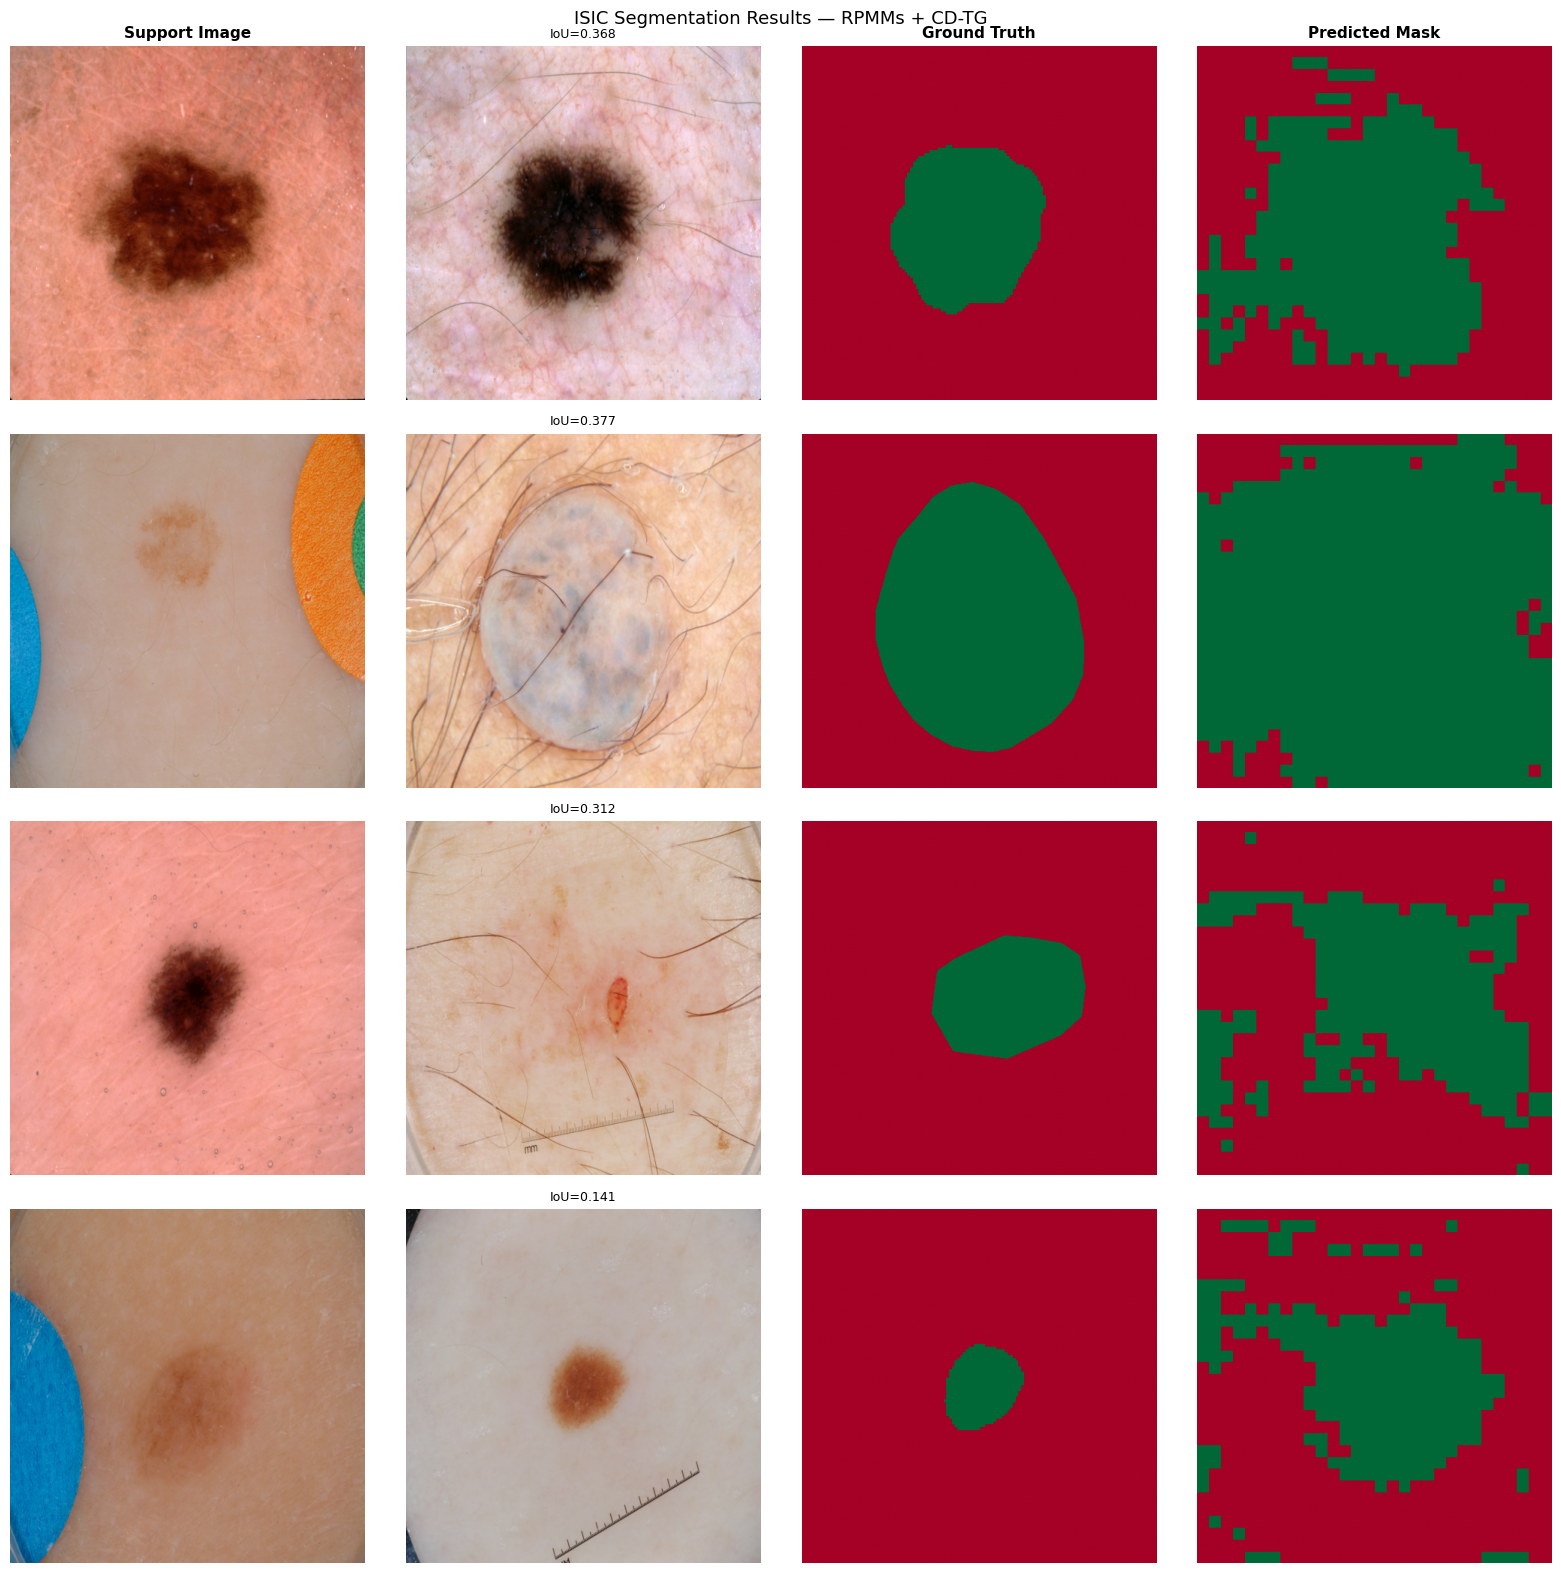

Qualitative results saved.


In [23]:
def denormalize(tensor):
    mean = torch.tensor(IMG_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMG_STD).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1)

# Get one batch from ISIC
isic_ds_viz = ISICFewShotDataset(cfg.ISIC_IMG_DIR, cfg.ISIC_MASK_DIR,
                                  shot=1, size=cfg.IMG_SIZE, n_episodes=20)
isic_loader_viz = DataLoader(isic_ds_viz, batch_size=4, shuffle=False, num_workers=2)
batch = next(iter(isic_loader_viz))

sup_imgs    = batch['support_imgs'].to(DEVICE)
sup_masks   = batch['support_masks'].to(DEVICE)
q_img       = batch['query_img'].to(DEVICE)
q_mask      = batch['query_mask'].to(DEVICE)
class_names = list(batch['class_name'])

with torch.no_grad():
    pred_logits, _ = model_cdtg(sup_imgs, sup_masks, q_img, class_names)

pred_masks    = (torch.sigmoid(pred_logits) > 0.5).float()
pred_masks_up = F.interpolate(pred_masks, size=(cfg.IMG_SIZE, cfg.IMG_SIZE), mode='nearest')

N_SHOW = min(4, len(q_img))
fig, axes = plt.subplots(N_SHOW, 4, figsize=(16, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[np.newaxis, :]

for ax, ct in zip(axes[0], ['Support Image','Query Image','Ground Truth','Predicted Mask']):
    ax.set_title(ct, fontsize=11, fontweight='bold')

for i in range(N_SHOW):
    sup_img_show = denormalize(sup_imgs[i, 0]).permute(1, 2, 0).numpy()
    q_img_show   = denormalize(q_img[i]).permute(1, 2, 0).numpy()
    gt_show      = q_mask[i, 0].cpu().numpy()
    pred_show    = pred_masks_up[i, 0].cpu().numpy()
    iou_i        = compute_iou(pred_logits[i:i+1], q_mask[i:i+1])

    axes[i,0].imshow(sup_img_show); axes[i,0].axis('off')
    axes[i,1].imshow(q_img_show);   axes[i,1].axis('off')
    axes[i,2].imshow(gt_show,  cmap='RdYlGn'); axes[i,2].axis('off')
    axes[i,3].imshow(pred_show, cmap='RdYlGn'); axes[i,3].axis('off')
    axes[i,1].set_title(f'IoU={iou_i:.3f}', fontsize=9)

plt.suptitle('ISIC Segmentation Results — RPMMs + CD-TG', fontsize=13)
plt.tight_layout()
plt.savefig('/kaggle/working/qualitative_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Qualitative results saved.')

In [31]:
class RPMMsModel(nn.Module):
    """Pure RPMMs — ResNet50 only, no CLIP, no text guidance."""
    def __init__(self, cfg):
        super().__init__()
        self.backbone  = ResNet50Backbone(out_dim=cfg.FEATURE_DIM)
        self.segmentor = RPMMSSegmentor(
            feat_dim=cfg.FEATURE_DIM,
            n_prototypes=cfg.N_PROTOTYPES
        )

    def forward(self, support_imgs, support_masks, query_img, class_names):
        B, K = support_imgs.shape[:2]
        sup_flat = support_imgs.view(B * K, *support_imgs.shape[2:])
        F_s_flat = self.backbone(sup_flat)
        C, h, w  = F_s_flat.shape[1:]
        F_s      = F_s_flat.view(B, K, C, h, w)
        F_q      = self.backbone(query_img)
        P_list = []
        for k in range(K):
            pm = mask_avg_pool(F_s[:, k], support_masks[:, k])
            P_list.append(pm)
        P_final        = torch.stack(P_list, dim=1).mean(dim=1)
        P_spatial      = P_final.unsqueeze(-1).unsqueeze(-1).expand(B, C, h, w)
        sup_feat_fused = P_spatial.unsqueeze(1)
        sup_mask_avg   = support_masks.float().mean(dim=1, keepdim=True)
        pred_logits, _ = self.segmentor(sup_feat_fused, sup_mask_avg, F_q)
        return pred_logits, torch.zeros(B, device=F_q.device)

print('RPMMsModel defined.')

RPMMsModel defined.


In [32]:
import os, shutil
from tqdm import tqdm

# Delete old wrong RPMMs models
for p in ['/kaggle/working/best_rpmms_1shot_model.pth',
          '/kaggle/working/best_rpmms_5shot_model.pth']:
    if os.path.exists(p):
        os.remove(p)
        print(f'Deleted: {p}')

def train_rpmms(shot, save_path):
    cfg.SHOT = shot
    model_r  = RPMMsModel(cfg).to(DEVICE)
    opt      = torch.optim.AdamW(
        [p for p in model_r.parameters() if p.requires_grad],
        lr=cfg.LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)

    sbd_ok   = os.path.exists(cfg.SBD_MASK_DIR)
    train_ds = PascalFewShotDataset(
        img_dir=cfg.PASCAL_IMG_DIR, mask_dir=cfg.PASCAL_MASK_DIR,
        split_dir=cfg.PASCAL_SPLIT_DIR, class_ids=cfg.VOC_TRAIN_IDS,
        shot=shot, split='train', size=cfg.IMG_SIZE,
        sbd_mask_dir=cfg.SBD_MASK_DIR if sbd_ok else None,
        sbd_split_file=cfg.SBD_SPLIT_FILE if sbd_ok else None,
    )
    train_loader = DataLoader(train_ds, batch_size=4,
                              shuffle=True, num_workers=2, pin_memory=True)
    isic_ds  = ISICFewShotDataset(cfg.ISIC_IMG_DIR, cfg.ISIC_MASK_DIR,
                                   shot=shot, size=cfg.IMG_SIZE, n_episodes=200)
    isic_loader = DataLoader(isic_ds, batch_size=4, shuffle=False, num_workers=2)

    best = 0.0
    for epoch in range(10):
        model_r.train()
        pbar = tqdm(train_loader, desc=f'RPMMs {shot}-shot Epoch {epoch+1}/10')
        for batch in pbar:
            si=batch['support_imgs'].to(DEVICE)
            sm=batch['support_masks'].to(DEVICE)
            qi=batch['query_img'].to(DEVICE)
            qm=batch['query_mask'].to(DEVICE)
            cn=list(batch['class_name'])
            opt.zero_grad()
            pred,_=model_r(si,sm,qi,cn)
            loss=binary_cross_entropy_loss(pred,qm)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_r.parameters(),1.0)
            opt.step()
            pbar.set_postfix({'loss':f'{loss.item():.4f}'})
        iou,_=evaluate(model_r, isic_loader, desc=f'ISIC {shot}-shot Epoch {epoch+1}')
        sch.step()
        print(f'Epoch {epoch+1}: ISIC={iou*100:.2f}%')
        if iou > best:
            best=iou
            torch.save(model_r.state_dict(), save_path)
            print(f'  Saved (ISIC={best*100:.2f}%)')
    print(f'Done. Best ISIC {shot}-shot: {best*100:.2f}%')
    return model_r

model_rpmms_1shot = train_rpmms(shot=1,
    save_path='/kaggle/working/best_rpmms_1shot_model.pth')
model_rpmms_5shot = train_rpmms(shot=5,
    save_path='/kaggle/working/best_rpmms_5shot_model.pth')

Deleted: /kaggle/working/best_rpmms_1shot_model.pth
Deleted: /kaggle/working/best_rpmms_5shot_model.pth
  SBD aug merged: 12031 extra IDs -> total 12031
PascalFewShot (train): 15 classes, 3524 samples
ISIC dataset: 2594 image-mask pairs found.


ISIC 1-shot Epoch 1: 100%|██████████| 50/50 [00:43<00:00,  1.14it/s]


Epoch 1: ISIC=21.83%
  Saved (ISIC=21.83%)


ISIC 1-shot Epoch 2: 100%|██████████| 50/50 [00:48<00:00,  1.04it/s]


Epoch 2: ISIC=24.14%
  Saved (ISIC=24.14%)


ISIC 1-shot Epoch 3: 100%|██████████| 50/50 [00:44<00:00,  1.12it/s]


... (31 outputs left out)

ISIC 5-shot Epoch 9: 100%|██████████| 50/50 [02:02<00:00,  2.45s/it]


Epoch 9: ISIC=20.56%


ISIC 5-shot Epoch 10: 100%|██████████| 50/50 [02:00<00:00,  2.40s/it]

Epoch 10: ISIC=20.95%
Done. Best ISIC 5-shot: 23.41%


In [36]:
model_rpmms_1shot.eval()
model_rpmms_5shot.eval()

print('Evaluating RPMMs 1-shot...')
results_rpmms_1shot = evaluate_all_datasets(
    model_rpmms_1shot, shot=1, desc_prefix='RPMMs')

print('Evaluating RPMMs 5-shot...')
results_rpmms_5shot = evaluate_all_datasets(
    model_rpmms_5shot, shot=5, desc_prefix='RPMMs')

# Print final table
paper_rpmms_1 = {'ISIC':18.0,'CXR':30.1,'WBC':22.0,'CHAOST2':10.3}
paper_rpmms_5 = {'ISIC':20.0,'CXR':30.8,'WBC':23.6,'CHAOST2':10.7}
paper_cdtg_1  = {'ISIC':36.2,'CXR':40.0,'WBC':27.9,'CHAOST2':15.4}
paper_cdtg_5  = {'ISIC':37.5,'CXR':40.4,'WBC':37.2,'CHAOST2':15.5}

print('='*95)
print('  FINAL RESULTS')
print('='*95)
print(f'  {"Dataset":<10} {"P.RPMMs 1s":>10} {"P.RPMMs 5s":>10} {"P.CDTG 1s":>10} {"P.CDTG 5s":>10} {"RPMMs 1s":>10} {"RPMMs 5s":>10} {"CDTG 1s":>10} {"CDTG 5s":>10}')
print(f'  {"-"*95}')
for ds in ['ISIC','CXR','WBC','CHAOST2']:
    print(f'  {ds:<10} '
          f'{paper_rpmms_1[ds]:>10.1f} {paper_rpmms_5[ds]:>10.1f} '
          f'{paper_cdtg_1[ds]:>10.1f} {paper_cdtg_5[ds]:>10.1f} '
          f'{results_rpmms_1shot.get(ds,0):>10.2f} '
          f'{results_rpmms_5shot.get(ds,0):>10.2f} '
          f'{results_cdtg_1shot.get(ds,0):>10.2f} '
          f'{results_cdtg_5shot.get(ds,0):>10.2f}')
print('='*95)

Evaluating RPMMs 1-shot...
ISIC dataset: 2594 image-mask pairs found.


RPMMs ISIC 1-shot: 100%|██████████| 50/50 [00:44<00:00,  1.11it/s]


ISIC 1-shot: 21.15%
ChestXRay: 704 pairs found.


RPMMs CXR 1-shot: 100%|██████████| 50/50 [00:44<00:00,  1.13it/s]


CXR 1-shot: 30.81%


RPMMs WBC 1-shot (nucleus):   0%|          | 0/25 [00:00<?, ?it/s]

... (31 outputs left out)

RPMMs CHAOS 5-shot (left_kidney): 100%|██████████| 25/25 [00:10<00:00,  2.43it/s]


CHAOS 5-shot left_kidney: 0.46%
CHAOST2 (spleen): 164 (cached)


RPMMs CHAOS 5-shot (spleen): 100%|██████████| 25/25 [00:10<00:00,  2.44it/s]

CHAOS 5-shot spleen: 0.32%
CHAOST2 5-shot mean: 0.43%
  FINAL RESULTS
  Dataset    P.RPMMs 1s P.RPMMs 5s  P.CDTG 1s  P.CDTG 5s   RPMMs 1s   RPMMs 5s    CDTG 1s    CDTG 5s
  -----------------------------------------------------------------------------------------------
  ISIC             18.0       20.0       36.2       37.5      21.15      20.06      31.74      33.18
  CXR              30.1       30.8       40.0       40.4      30.81      26.18      49.25      41.10
  WBC              22.0       23.6       27.9       37.2      19.38      14.50      26.76      42.41
  CHAOST2          10.3       10.7       15.4       15.5       0.56       0.43       0.99       0.83
